In [1]:
import sys
from pathlib import Path
ROOT_DIR = Path.cwd().parent
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

import pandas as pd
import joblib
from src.Preprocessing import separer_types, cree_preprocessing
from src.train import (
    create_models, train_models, evaluate_all_models,
    create_resultats_dataframe, plot_confusion_matrices, save_best_model
)

In [2]:
DATA_PATH = "../data/processed"
x_train = pd.read_csv(f"{DATA_PATH}/x_train.csv")
y_train = pd.read_csv(f"{DATA_PATH}/y_train.csv").squeeze("columns")
x_test  = pd.read_csv(f"{DATA_PATH}/x_test.csv")
y_test  = pd.read_csv(f"{DATA_PATH}/y_test.csv").squeeze("columns")
print("x_train:", x_train.shape, "| x_test:", x_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)
print("\nDistribution y_train:")
print(y_train.value_counts(normalize=True).round(3))

x_train: (1600, 15) | x_test: (400, 15)
y_train: (1600,) | y_test: (400,)

Distribution y_train:
Mental_Health_Risk
High      0.34
Medium    0.33
Low       0.33
Name: proportion, dtype: float64


In [3]:
num_col, cat_col = separer_types(x_train)
preprocessor = cree_preprocessing(num_col, cat_col)

variable numeriques: ['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']
variable categorielles: ['Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History']


In [4]:
models = create_models(preprocessor)
models = train_models(models, x_train, y_train)

Entrainement des models: 
Entrainement: Logistic Regression
Entrainement: Random Forest
Entrainement: Linear SVM


c:\Users\safiy\Desktop\ProjetsPython\mental_health_prediction\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [5]:
all_res, con_mat = evaluate_all_models(models, x_test, y_test)

Evaluation des models: 
Accuracy: 0.7575
Precision: 0.7570
Recall: 0.7568
F1-score: 0.7569
Roc-Auc: 0.9140

 matrice de confusion: 
[[112   0  24]
 [  1 107  24]
 [ 25  23  84]]
Accuracy: 0.7025
Precision: 0.6994
Recall: 0.7017
F1-score: 0.7003
Roc-Auc: 0.8556

 matrice de confusion: 
[[106   3  27]
 [  2 103  27]
 [ 34  26  72]]
Accuracy: 0.7250
Precision: 0.7230
Recall: 0.7242
F1-score: 0.7235
Roc-Auc: 0.8903

 matrice de confusion: 
[[109   1  26]
 [  2 104  26]
 [ 24  31  77]]


In [6]:
res_df = create_resultats_dataframe(all_res)
res_df

Comparaison des models: 
                     Accuracy  Precision  Recall  F1-score  Roc-Auc
Logistic Regression    0.7575     0.7570  0.7568    0.7569   0.9140
Random Forest          0.7025     0.6994  0.7017    0.7003   0.8556
Linear SVM             0.7250     0.7230  0.7242    0.7235   0.8903


,Accuracy,Precision,Recall,F1-score,Roc-Auc
Logistic Regression,0.7575,0.7570,0.7568,0.7569,0.9140
Random Forest,0.7025,0.6994,0.7017,0.7003,0.8556
Linear SVM,0.7250,0.7230,0.7242,0.7235,0.8903


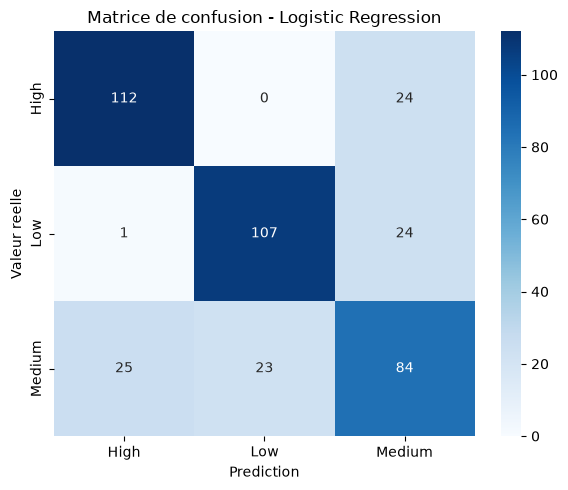

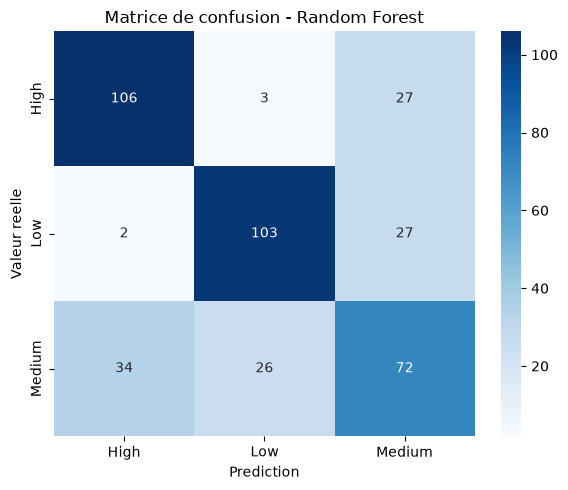

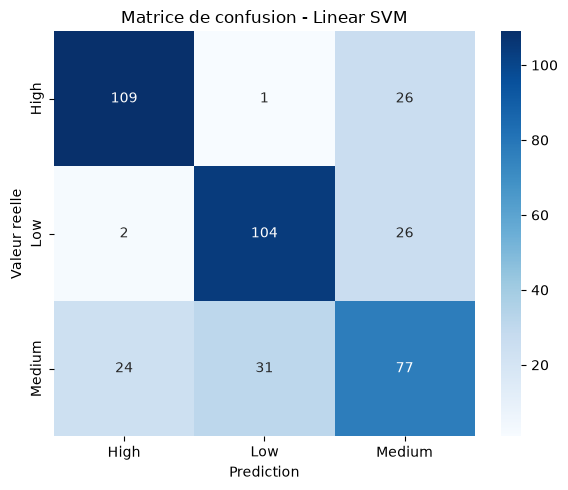

In [7]:
plot_confusion_matrices(models, x_test, y_test)

In [8]:
best_name, pipeline_path = save_best_model(models, res_df, path="../models")

meilleur modele: Logistic Regression
F1-score CV: 0.7569
sauvegarde dans: ../models\best_model.pkl
